# 2.5 Poisson Regression: Practice

**Regression Analysis · Unit 2**

> **Risk team asks:** Which portfolio segments file more claims, once we account for how many policy-years each one has?
>
> **Pricing team asks:** How many claims should we expect from a new segment we are about to insure?

In the theory class we built the model. Today we fit it, read it, check it, and test it on data it has not seen.

**What you will do**

1. Look at counts as rates.
2. Split the data into training and test sets.
3. Fit a Poisson model with an offset and read the rate ratios.
4. Check the fit and the dispersion.
5. Predict on test data.
6. Handle overdispersion.

**Data files:** `auto_insurance_claims.csv` and `auto_insurance_claims_extra_variation.csv`

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_poisson_deviance, mean_absolute_error

# Course colors for this unit
BROWN, MID, SAND, TERRA = "#4E342E", "#8D6E4F", "#D9C3A0", "#B5523B"

plt.rcParams.update({"figure.dpi": 110,
                     "axes.spines.top": False,
                     "axes.spines.right": False})

## 2. The data

Each row is one **portfolio segment** (a group of policies), not a single policy. For example, think of each row as the portfolio of one branch for one customer profile.

| Column | Meaning |
|---|---|
| `segment_id` | Identifier of the segment (S001 to S240). It only names the row; we do not use it as a predictor |
| `region` | Urban or Rural |
| `driver_age` | Young or Adult (the main driver group of the segment) |
| `vehicle_age` | Average age of the vehicles in the segment, in years |
| `policy_years` | **Exposure**: total years of coverage in the segment |
| `claims` | Number of claims filed. This is our response (a count) |

In [2]:
df = pd.read_csv("auto_insurance_claims.csv")
df.head()

,segment_id,region,driver_age,vehicle_age,policy_years,claims
0,S001,Urban,Adult,8,126,11
1,S002,Rural,Young,10,199,22
2,S003,Rural,Adult,3,187,15
3,S004,Urban,Adult,2,287,33
4,S005,Rural,Adult,5,139,11


In [3]:
print("Unique segment ids:", df["segment_id"].is_unique)

df.info()
df.describe().round(1)

Unique segment ids: True
<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   segment_id    240 non-null    str  
 1   region        240 non-null    str  
 2   driver_age    240 non-null    str  
 3   vehicle_age   240 non-null    int64
 4   policy_years  240 non-null    int64
 5   claims        240 non-null    int64
dtypes: int64(3), str(3)
memory usage: 14.7 KB


,vehicle_age,policy_years,claims
count,240.0,240.0,240.0
mean,7.4,333.8,30.5
std,4.6,154.1,18.2
min,0.0,85.0,2.0
25%,3.0,195.8,16.0
50%,7.0,332.0,29.5
75%,12.0,467.5,40.0
max,15.0,599.0,108.0


The data is already clean: no missing values and the right types. We can go straight to the question.

## 3. Counts need context

A segment with more policy-years will file more claims, even if its drivers are not riskier. Look at how claims grow with exposure.

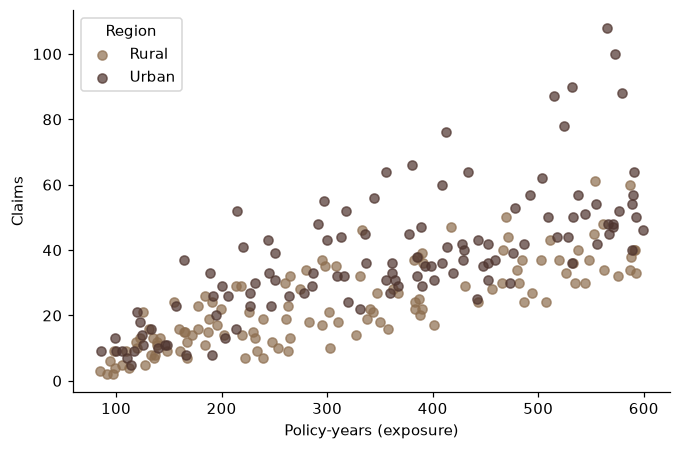

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for region, color in [("Rural", MID), ("Urban", BROWN)]:
    subset = df[df["region"] == region]
    ax.scatter(subset["policy_years"], subset["claims"], color=color, alpha=0.7, label=region)
ax.set_xlabel("Policy-years (exposure)")
ax.set_ylabel("Claims")
ax.legend(title="Region")
plt.show()

Now compare **rates** instead of counts. For each group, add up the claims and the policy-years first, then divide.

In [5]:
rates = df.groupby(["region", "driver_age"]).agg(claims=("claims", "sum"),
                                                 policy_years=("policy_years", "sum"))
rates["claims_per_policy_year"] = rates["claims"] / rates["policy_years"]
rates.round(4)

claims  policy_years  claims_per_policy_year
region driver_age                                              
Rural  Adult         1692         27370                  0.0618
       Young         1179         11208                  0.1052
Urban  Adult         2702         30488                  0.0886
       Young         1756         11038                  0.1591

**Question 1.** Which group has the highest claim rate? Which group files the most claims in total? Are they the same group? Why?

**Your answer:** Urban young

&nbsp;

## 4. Prepare the predictors

We use the same approach as in the linear regression notebook: one-hot columns with **explicit reference categories**. The references are **Rural** and **Adult**.

The **offset** is `log(policy_years)`.

### What is an offset?

Segments have different sizes. A segment with 600 policy-years will file more claims than one with 100, even if its drivers are not riskier. We want to compare **rates** (claims per policy-year), not raw counts.

To do that, the model uses `log(policy_years)` as a known number added to the equation. This is the **offset**. Its coefficient is fixed at 1, so the model does not estimate it and it does not appear in the summary table.

In Python, we pass it with `offset=` when we create the model. If you forget it, the code still runs, but the results are wrong. You will see this in section 6.

In [6]:
X = pd.get_dummies(df[["region", "driver_age"]], dtype=float)
X = X.drop(columns=["region_Rural", "driver_age_Adult"])          # reference categories
X = X.rename(columns={"region_Urban": "Urban", "driver_age_Young": "Young"})
X["vehicle_age"] = df["vehicle_age"].astype(float)
X = sm.add_constant(X)

y = df["claims"]
offset = np.log(df["policy_years"])

X.head()

,const,Urban,Young,vehicle_age
0,1.0,1.0,0.0,8.0
1,1.0,0.0,1.0,10.0
2,1.0,0.0,0.0,3.0
3,1.0,1.0,0.0,2.0
4,1.0,0.0,0.0,5.0


## 5. Split the data

As in the linear regression notebook, we split first. We use **80% of the segments (training)** to build and check the model, and we keep **20% (test)** for the end, to see how it predicts new segments.

From here until section 8, every model is fitted on the **training** data only.

In [7]:
X_train, X_test, y_train, y_test, off_train, off_test = train_test_split(
    X, y, offset, test_size=0.20, random_state=42)

print("Training segments:", len(X_train))
print("Test segments:", len(X_test))

Training segments: 192
Test segments: 48


## 6. First, a model without the offset (on purpose)

Let us see what happens if we forget the exposure.

In [8]:
poisson_no_offset = sm.GLM(y_train, X_train, family=sm.families.Poisson()).fit()

print("Residual deviance:", round(poisson_no_offset.deviance, 1))
print("Degrees of freedom:", int(poisson_no_offset.df_resid))
print("Deviance / df:", round(poisson_no_offset.deviance / poisson_no_offset.df_resid, 2))

Residual deviance: 1406.1
Degrees of freedom: 188
Deviance / df: 7.48


**Question 2.** A well-fitted Poisson model has deviance / df close to 1. What do you see here? Why does it happen?

**Your answer:** porque el offset fue aplicado correctamente y la desviación es similar a los grados de libertad

&nbsp;

## 7. The Poisson model with offset

The offset goes in as an argument when we create the model. It will **not** appear as a row in the table: its coefficient is fixed at 1, so nothing is estimated for it.

In [9]:
poisson = sm.GLM(y_train, X_train, family=sm.families.Poisson(), offset=off_train).fit()
print(poisson.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 claims   No. Observations:                  192
Model:                            GLM   Df Residuals:                      188
Model Family:                 Poisson   Df Model:                            3
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -592.84
Date:                Thu, 12 Nov 2026   Deviance:                       208.23
Time:                        19:05:38   Pearson chi2:                     204.
No. Iterations:                     5   Pseudo R-squ. (CS):             0.9636
Covariance Type:            nonrobust                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -2.8292      0.032    -88.015      

Now build a results table with one row per coefficient and these columns: `coef`, `std_err`, `p_value`, and `rate_ratio` (the exponential of the coefficient).

In [10]:
# YOUR CODE HERE
results = pd.DataFrame({
    "coef": poisson.params,
    "std_err": poisson.bse,
    "p_value": poisson.pvalues,
    "rate_ratio": np.exp(poisson.params)
}).round(4)

print(results)

               coef  std_err  p_value  rate_ratio
const       -2.8292   0.0321   0.0000      0.0591
Urban        0.3973   0.0269   0.0000      1.4878
Young        0.5755   0.0264   0.0000      1.7780
vehicle_age  0.0023   0.0029   0.4146      1.0024


**Example (given): the intercept.** Its rate ratio is exp(−2.83) = 0.059. This is the **baseline rate**: for a Rural segment with Adult drivers and vehicles of age 0, we expect about 0.059 claims per policy-year (about 6 claims for every 100 policy-years).

**Question 3.** Now it is your turn. Explain `Urban`, `Young`, and `vehicle_age` to the Risk team, one sentence for each. Which one would you **not** present as an effect, and why?

**Your answer:** la edad del vehículo no influye tanto como si es urbano o rural, ni como la edad del conductor. Los jóvenes que manejan en zonas urbanas corren muchos más riesgos.

&nbsp;

## 8. How well does it fit?

First the numbers that `statsmodels` gives us (training data).

In [11]:
print("Observations:", int(poisson.nobs))
print("Residual degrees of freedom:", int(poisson.df_resid))
print("Null deviance:", round(poisson.null_deviance, 1))
print("Residual deviance:", round(poisson.deviance, 1))
print("AIC:", round(poisson.aic, 1))

Observations: 192
Residual degrees of freedom: 188
Null deviance: 844.1
Residual deviance: 208.2
AIC: 1193.7


Now compute three more numbers yourself and print them:

- the **pseudo-R²** based on deviance,
- the dispersion as **deviance / df**,
- the dispersion as **Pearson chi-square / df**.

In [12]:
# YOUR CODE HERE
pseudo_r2 = 1 - poisson.deviance / poisson.null_deviance
dispersion_dev = poisson.deviance / poisson.df_resid
dispersion_pearson = poisson.pearson_chi2 / poisson.df_resid

print("Pseudo-R² (deviance):", round(pseudo_r2, 3))
print("Deviance / df:", round(dispersion_dev, 2))
print("Pearson chi-square / df:", round(dispersion_pearson, 2))

Pseudo-R² (deviance): 0.753
Deviance / df: 1.11
Pearson chi-square / df: 1.08


As always, we look at plots too. Observed vs. expected claims, and the Pearson residuals.

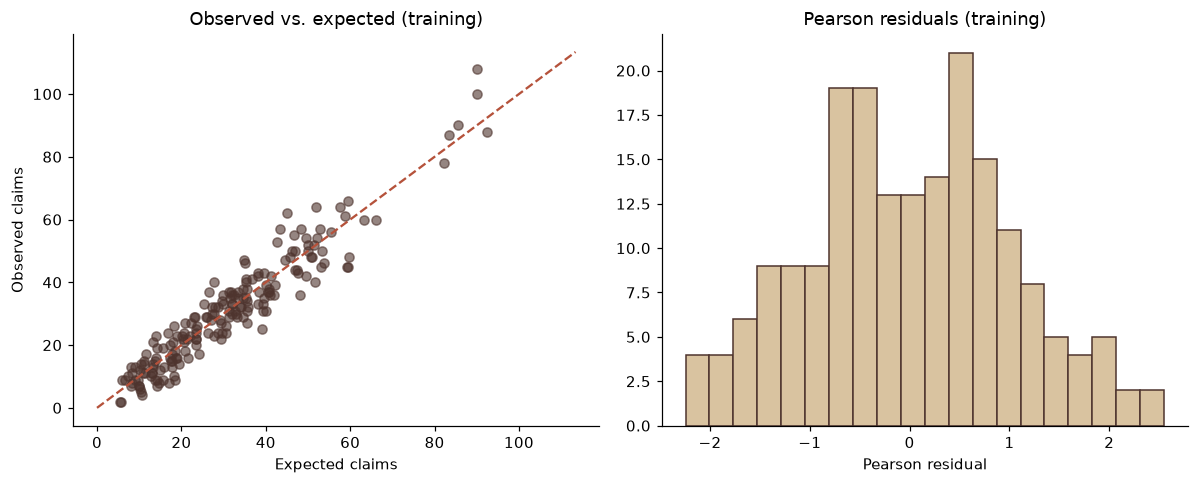

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(poisson.fittedvalues, y_train, color=BROWN, alpha=0.6)
limit = [0, max(y_train.max(), poisson.fittedvalues.max()) * 1.05]
axes[0].plot(limit, limit, color=TERRA, linestyle="--")
axes[0].set_xlabel("Expected claims")
axes[0].set_ylabel("Observed claims")
axes[0].set_title("Observed vs. expected (training)")

axes[1].hist(poisson.resid_pearson, bins=20, color=SAND, edgecolor=BROWN)
axes[1].set_xlabel("Pearson residual")
axes[1].set_title("Pearson residuals (training)")

plt.tight_layout()
plt.show()

**Question 4.** Is a dispersion around 1.1 a problem? What do the two plots tell you?

**Your answer:** no es un problema, observamos que las observaciones están pegadas a la línea de la expectativa.

&nbsp;

## 9. Does it predict new data?

Fit and prediction are different things. Deviance and AIC use the same data that estimated the model. Now we use the **test set**: 48 segments that the model has never seen.

We compare the model with a **baseline**: the same claim rate for every segment, multiplied by its exposure.

In [14]:
# Expected claims on the test data. The offset is required.
expected_test = poisson.predict(X_test, offset=off_test)

# Baseline: one overall rate from the training data
baseline_rate = y_train.sum() / np.exp(off_train).sum()
expected_baseline = baseline_rate * np.exp(off_test)

metrics = pd.DataFrame({
    "mean Poisson deviance": [mean_poisson_deviance(y_test, expected_test),
                              mean_poisson_deviance(y_test, expected_baseline)],
    "MAE": [mean_absolute_error(y_test, expected_test),
            mean_absolute_error(y_test, expected_baseline)],
}, index=["Poisson model", "Baseline (same rate for all)"]).round(2)
metrics

,mean Poisson deviance,MAE
Poisson model,1.39,4.79
Baseline (same rate for all),4.24,8.43


Now check the **calibration**. For each combination of `region` and `driver_age` in the test set, add up the observed claims and the expected claims, and then divide observed by expected. Then add one more row with the totals of the whole test set.

*Add up first, then divide. Do not average the ratios of single segments.*

In [15]:
test = df.loc[X_test.index, ["region", "driver_age"]].copy()
test["observed"] = y_test
test["expected"] = expected_test

# YOUR CODE HERE: calibration table by region and driver_age, plus a totals row
calibration = test.groupby(["region", "driver_age"])[["observed", "expected"]].sum()
calibration["segments"] = test.groupby(["region", "driver_age"]).size()
calibration.loc[("Total", "All"), :] = [test["observed"].sum(), test["expected"].sum(), len(test)]
calibration["observed / expected"] = calibration["observed"] / calibration["expected"]
calibration.round(2)

observed  expected  segments  observed / expected
region driver_age                                                   
Rural  Adult          505.0    458.90      24.0                 1.10
       Young          152.0    172.63       6.0                 0.88
Urban  Adult          361.0    380.94      10.0                 0.95
       Young          314.0    312.16       8.0                 1.01
Total  All           1332.0   1324.63      48.0                 1.01

The same comparison as a plot. It needs the `calibration` table from the previous cell.

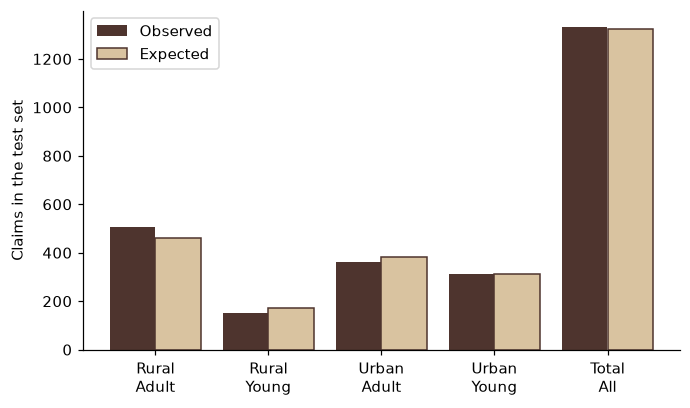

In [16]:
labels = [f"{r}\n{d}" for r, d in calibration.index]
positions = np.arange(len(calibration))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(positions - 0.2, calibration["observed"], width=0.4, color=BROWN, label="Observed")
ax.bar(positions + 0.2, calibration["expected"], width=0.4, color=SAND, edgecolor=BROWN, label="Expected")
ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_ylabel("Claims in the test set")
ax.legend()
plt.show()

**Question 5.** Does the model beat the baseline? Is it well calibrated? How much would you trust a ratio of 0.88 in a group of 6 segments?

**Your answer:**

&nbsp;

## 10. The Pricing team question

How many claims should we expect from a new segment: **Urban**, **Young** drivers, vehicle age **5** years, and **300 policy-years**?

In [17]:
new_segment = pd.DataFrame({"const": [1.0], "Urban": [1.0], "Young": [1.0], "vehicle_age": [5.0]})

expected_claims = poisson.predict(new_segment, offset=np.log([300]))
expected_rate = poisson.predict(new_segment)   # sin offset: log(1) = 0, tasa por póliza-año

print("Expected claims: ", round(float(expected_claims.iloc[0]), 1))
print("Expected rate (claims per policy-year): ", round(float(expected_rate.iloc[0]), 3))

Expected claims:  47.4
Expected rate (claims per policy-year):  0.158


**Question 6.** What does `predict` return if you do **not** pass the offset? Why is that dangerous?

**Your answer:**

&nbsp;

## 11. When Poisson does not hold: overdispersion

The data team sends a second portfolio. It has the **same segments and the same predictors**, but customers inside each segment differ a lot (for example, in how they drive), and the model does not see that. We use the same training and test split.

In [18]:
df2 = pd.read_csv("auto_insurance_claims_extra_variation.csv")

same_predictors = (df2[["region", "driver_age", "vehicle_age", "policy_years"]]
                   == df[["region", "driver_age", "vehicle_age", "policy_years"]]).all().all()
print("Same predictors as before:", same_predictors)

y2_train = df2.loc[X_train.index, "claims"]
poisson2 = sm.GLM(y2_train, X_train, family=sm.families.Poisson(), offset=off_train).fit()

print("Deviance / df:", round(poisson2.deviance / poisson2.df_resid, 2))
print("Pearson chi-square / df:", round(poisson2.pearson_chi2 / poisson2.df_resid, 2))

Same predictors as before: True
Deviance / df: 2.95
Pearson chi-square / df: 2.99


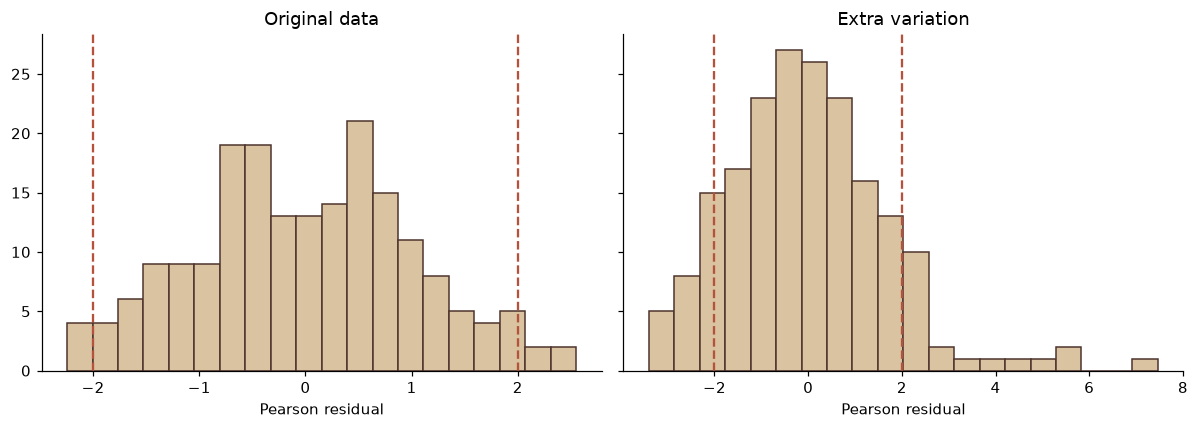

Share of residuals outside ±2, original data: 0.057
Share of residuals outside ±2, extra variation: 0.234


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, model, title in [(axes[0], poisson, "Original data"), (axes[1], poisson2, "Extra variation")]:
    ax.hist(model.resid_pearson, bins=20, color=SAND, edgecolor=BROWN)
    ax.axvline(-2, color=TERRA, linestyle="--")
    ax.axvline(2, color=TERRA, linestyle="--")
    ax.set_xlabel("Pearson residual")
    ax.set_title(title)
plt.tight_layout()
plt.show()

print("Share of residuals outside ±2, original data:", round((abs(poisson.resid_pearson) > 2).mean(), 3))
print("Share of residuals outside ±2, extra variation:", round((abs(poisson2.resid_pearson) > 2).mean(), 3))

### If the Poisson assumption does not hold

**What happens in general.** The variance is larger than the mean. The coefficients are usually still reasonable, but the standard errors are too small. P-values look better than they are.

**How it shows in this model.** The dispersion is about 3 instead of 1, and about 23% of the Pearson residuals are outside ±2 (we expect about 5%).

**Remedies.** Three common options:

1. **Quasi-Poisson:** same coefficients, standard errors multiplied by the square root of the dispersion.
2. **Robust standard errors:** do not rely on variance = mean.
3. **Negative binomial:** a different model with an extra parameter for the extra variation.

Fit the three remedies on the second portfolio.

In [20]:
# Quasi-Poisson and robust standard errors are options of .fit(); the negative binomial is its own model.
# YOUR CODE HERE
quasi = sm.GLM(y2_train, X_train, family=sm.families.Poisson(), offset=off_train).fit(scale="X2")
robust = sm.GLM(y2_train, X_train, family=sm.families.Poisson(), offset=off_train).fit(cov_type="HC0")
negbin = sm.NegativeBinomial(y2_train, X_train, offset=off_train).fit(disp=0)

print("Negative binomial, alpha:", round(negbin.params["alpha"], 3))

Negative binomial, alpha: 0.06


Now compare what each method says about `vehicle_age`.

In [21]:
models = {"Poisson": poisson2, "Quasi-Poisson": quasi, "Robust SE": robust, "Negative binomial": negbin}

comparison = pd.DataFrame({
    "coef": [m.params["vehicle_age"] for m in models.values()],
    "std_err": [m.bse["vehicle_age"] for m in models.values()],
    "p_value": [m.pvalues["vehicle_age"] for m in models.values()],
}, index=list(models.keys())).round(4)

print(comparison)

                     coef  std_err  p_value
Poisson            0.0064   0.0029   0.0276
Quasi-Poisson      0.0064   0.0050   0.2024
Robust SE          0.0064   0.0057   0.2624
Negative binomial  0.0037   0.0051   0.4671


**Question 7.** Would you tell the Risk team that vehicle age changes the claim rate? Use the table to justify your answer.

**Your answer:**

&nbsp;

## 12. Wrap-up

Write a short answer, in plain language, for each team. Use numbers from your results.

- **Risk team:** Which segments file more claims, once we account for exposure?
- **Pricing team:** How many claims do we expect from the new segment? What should we check before trusting the model?

**Your answer for the Risk team:**

&nbsp;

**Your answer for the Pricing team:**

&nbsp;

### Things to remember

- Model **rates**, not raw counts: the offset is `log(exposure)`, passed as an argument, and it never appears in the table.
- Split first: build and check the model on training data, and use the test data to see how it predicts.
- Read the coefficients as **rate ratios**: `exp(coef)`, with the other variables held constant.
- Do not interpret a coefficient that is not significant.
- Fit is not prediction: check calibration on test data (add up first, then divide).
- Check the dispersion. If it is far above 1, use quasi-Poisson, robust standard errors, or a negative binomial.